# Responsible and Safe AI (AIML4001) – External Practical, Set A
## Adversarial Attacks on an Automated Cheque-Amount Digit Reader
**ID:** 23CE050 &nbsp;|&nbsp; **Repository:** https://github.com/Samarth305/23CE050_Responsible_And_Safe_AI.git

Dataset: MNIST (60,000 train / 10,000 test, 28×28 grey-scale). Tools: Python 3, PyTorch, Torchvision, NumPy, Matplotlib (FGSM and PGD coded directly).
Guidelines: `torch.manual_seed(42)`, CPU only, pixel values in [0, 1], at most 2 epochs per training phase.

### Cell 1 – Imports

In [1]:
import copy
import json
import os

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

print("PyTorch", torch.__version__)

PyTorch 2.14.1+cu130


### Cell 2 – Configuration (as specified in the question paper)

In [2]:
torch.manual_seed(42)
DEVICE = torch.device("cpu")
BATCH_SIZE = 64
LR = 0.001
EPOCHS = 2                      # baseline training
ADV_EPOCHS = 2                  # adversarial fine-tuning
EPSILONS = [0.05, 0.10, 0.20, 0.30]
ADV_TRAIN_EPS = 0.20
PGD_STEPS = 10                  # alpha = eps / 4, random start

OUT_DIR = "."
DATA_DIR = "./data"

### Cell 3 – Load MNIST (ToTensor only → pixel values in [0, 1])

In [3]:
transform = transforms.ToTensor()
train_set = datasets.MNIST(DATA_DIR, train=True, download=True, transform=transform)
test_set = datasets.MNIST(DATA_DIR, train=False, download=True, transform=transform)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_set, batch_size=1000, shuffle=False)
print("Train:", len(train_set), " Test:", len(test_set))

100%|██████████| 9.91M/9.91M [00:00<00:00, 15.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 407kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.78MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.5MB/s]

Train: 60000  Test: 10000


### Cell 4 – Task 1: Baseline CNN (two convolution layers + two fully connected layers)

In [4]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3)    # 28 -> 26 -> pool 13
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3)   # 13 -> 11 -> pool 5
        self.fc1 = nn.Linear(64 * 5 * 5, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

### Cell 5 – Task 2: FGSM attack  
`x_adv = clip(x + ε · sign(∇ₓ L(f(x), y)), 0, 1)`

In [5]:
def fgsm_attack(model, x, y, eps):
    x_adv = x.clone().detach().requires_grad_(True)
    loss = F.cross_entropy(model(x_adv), y)
    grad = torch.autograd.grad(loss, x_adv)[0]
    x_adv = x_adv + eps * grad.sign()
    return torch.clamp(x_adv, 0.0, 1.0).detach()

### Cell 6 – Task 3: PGD attack (L∞, 10 iterations, α = ε/4, random start)

In [6]:
def pgd_attack(model, x, y, eps, steps=PGD_STEPS):
    alpha = eps / 4
    # random start inside the eps-ball
    x_adv = x + torch.empty_like(x).uniform_(-eps, eps)
    x_adv = torch.clamp(x_adv, 0.0, 1.0).detach()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        loss = F.cross_entropy(model(x_adv), y)
        grad = torch.autograd.grad(loss, x_adv)[0]
        x_adv = x_adv.detach() + alpha * grad.sign()
        # project back onto the L-inf ball around x and the valid pixel range
        x_adv = torch.min(torch.max(x_adv, x - eps), x + eps)
        x_adv = torch.clamp(x_adv, 0.0, 1.0).detach()
    return x_adv

### Cell 7 – Helper functions: training (clean / 50:50 adversarial) and evaluation

In [7]:
def train_epoch(model, optimizer, adversarial=False):
    model.train()
    total_loss, n = 0.0, 0
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        if adversarial:
            # Task 5: 50:50 mix of clean and FGSM (eps = 0.20) images
            model.eval()
            x_adv = fgsm_attack(model, x, y, ADV_TRAIN_EPS)
            model.train()
            x_in = torch.cat([x, x_adv], dim=0)
            y_in = torch.cat([y, y], dim=0)
        else:
            x_in, y_in = x, y
        optimizer.zero_grad()
        loss = F.cross_entropy(model(x_in), y_in)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x_in.size(0)
        n += x_in.size(0)
    return total_loss / n


def evaluate(model, attack=None, eps=0.0):
    """Accuracy (%) on the full 10,000-image test set, optionally under attack."""
    model.eval()
    correct = 0
    for x, y in test_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        if attack is not None and eps > 0:
            x = attack(model, x, y, eps)
        with torch.no_grad():
            correct += (model(x).argmax(1) == y).sum().item()
    return 100.0 * correct / len(test_set)

### Cell 8 – Task 1: Train the baseline CNN (Adam, lr = 0.001, batch 64, 2 epochs)

In [8]:
model = CNN().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
print(f"Training baseline CNN ({EPOCHS} epochs)...")
for ep in range(1, EPOCHS + 1):
    loss = train_epoch(model, optimizer)
    print(f"  epoch {ep}/{EPOCHS}  train loss = {loss:.4f}")
print("Training baseline CNN (2 epochs)... done.")
torch.save(model.state_dict(), os.path.join(OUT_DIR, "baseline_cnn.pt"))

clean_acc = evaluate(model)
print(f"Clean test accuracy : {clean_acc:.1f} %")

Training baseline CNN (2 epochs)...
  epoch 1/2  train loss = 0.1974
  epoch 2/2  train loss = 0.0567
Training baseline CNN (2 epochs)... done.
Clean test accuracy : 98.7 %


### Cell 9 – Tasks 2 & 3: FGSM and PGD accuracy for ε = 0.05, 0.10, 0.20, 0.30

In [9]:
fgsm_acc = {0.0: clean_acc}
pgd_acc = {0.0: clean_acc}
for eps in EPSILONS:
    fgsm_acc[eps] = evaluate(model, fgsm_attack, eps)
    pgd_acc[eps] = evaluate(model, pgd_attack, eps)

print("EPSILON    FGSM_ACC    PGD_ACC")
print("-------------------------------")
for eps in [0.0] + EPSILONS:
    print(f" {eps:.2f}      {fgsm_acc[eps]:5.1f} %     {pgd_acc[eps]:5.1f} %")
print("-------------------------------")

EPSILON    FGSM_ACC    PGD_ACC
-------------------------------
 0.00       98.7 %      98.7 %
 0.05       95.5 %      94.9 %
 0.10       86.4 %      79.6 %
 0.20       36.5 %       4.2 %
 0.30        2.9 %       0.0 %
-------------------------------


### Cell 10 – Task 4: 5 clean digits vs FGSM adversarial versions (ε = 0.20)

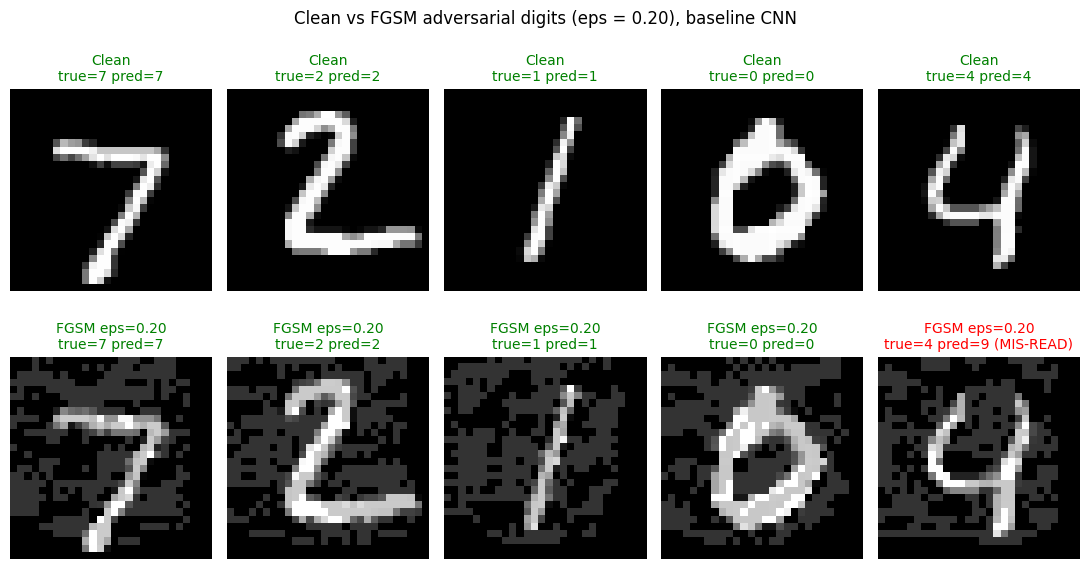

Mis-read digits saved : clean_vs_adversarial.png
  digit 1: true=7  clean pred=7  FGSM pred=7  -> correct
  digit 2: true=2  clean pred=2  FGSM pred=2  -> correct
  digit 3: true=1  clean pred=1  FGSM pred=1  -> correct
  digit 4: true=0  clean pred=0  FGSM pred=0  -> correct
  digit 5: true=4  clean pred=4  FGSM pred=9  -> MIS-READ
Attack success (eps=0.20): FGSM 63.5 %, PGD 95.8 %


In [10]:
model.eval()
x5, y5 = next(iter(DataLoader(test_set, batch_size=5, shuffle=False)))
x5_adv = fgsm_attack(model, x5, y5, 0.20)
with torch.no_grad():
    p_clean = model(x5).argmax(1)
    p_adv = model(x5_adv).argmax(1)

fig, axes = plt.subplots(2, 5, figsize=(11, 6.2))
misread = []
for i in range(5):
    axes[0, i].imshow(x5[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(f"Clean\ntrue={y5[i].item()} pred={p_clean[i].item()}",
                         fontsize=10, color="green" if p_clean[i] == y5[i] else "red")
    axes[1, i].imshow(x5_adv[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    wrong = p_adv[i] != y5[i]
    axes[1, i].set_title(f"FGSM eps=0.20\ntrue={y5[i].item()} pred={p_adv[i].item()}"
                         + (" (MIS-READ)" if wrong else ""),
                         fontsize=10, color="red" if wrong else "green")
    if wrong:
        misread.append((y5[i].item(), p_adv[i].item()))
    for r in range(2):
        axes[r, i].axis("off")
fig.suptitle("Clean vs FGSM adversarial digits (eps = 0.20), baseline CNN")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "clean_vs_adversarial.png"), dpi=150)
plt.show()

print("Mis-read digits saved : clean_vs_adversarial.png")
for i in range(5):
    status = "MIS-READ" if p_adv[i] != y5[i] else "correct"
    print(f"  digit {i + 1}: true={y5[i].item()}  clean pred={p_clean[i].item()}  "
          f"FGSM pred={p_adv[i].item()}  -> {status}")
print(f"Attack success (eps=0.20): FGSM {100 - fgsm_acc[0.20]:.1f} %, "
      f"PGD {100 - pgd_acc[0.20]:.1f} %")

### Cell 11 – Task 5: Adversarial training (2 epochs, 50:50 clean + FGSM ε = 0.20) and re-evaluation

In [11]:
adv_model = copy.deepcopy(model)
adv_opt = torch.optim.Adam(adv_model.parameters(), lr=LR)
print(f"Adversarial fine-tuning ({ADV_EPOCHS} epochs, 50:50 clean + FGSM eps=0.20)...")
for ep in range(1, ADV_EPOCHS + 1):
    loss = train_epoch(adv_model, adv_opt, adversarial=True)
    print(f"  epoch {ep}/{ADV_EPOCHS}  train loss = {loss:.4f}")
print("Adversarial fine-tuning... done.")
torch.save(adv_model.state_dict(), os.path.join(OUT_DIR, "adv_trained_cnn.pt"))

adv_clean = evaluate(adv_model)
adv_fgsm = evaluate(adv_model, fgsm_attack, 0.20)
adv_pgd = evaluate(adv_model, pgd_attack, 0.20)

Adversarial fine-tuning (2 epochs, 50:50 clean + FGSM eps=0.20)...
  epoch 1/2  train loss = 0.2523
  epoch 2/2  train loss = 0.1506
Adversarial fine-tuning... done.


### Cell 12 – Task 6: Baseline vs adversarially-trained table

In [12]:
print("MODEL              CLEAN    FGSM(0.20)   PGD(0.20)")
print("----------------------------------------------------")
print(f"Baseline           {clean_acc:.1f} %     {fgsm_acc[0.20]:.1f} %       {pgd_acc[0.20]:.1f} %")
print(f"Adversarially      {adv_clean:.1f} %     {adv_fgsm:.1f} %       {adv_pgd:.1f} %")
print("trained")
print("----------------------------------------------------")
print(f"Clean accuracy change : {adv_clean - clean_acc:+.1f} %")
print(f"FGSM robustness gain : {adv_fgsm - fgsm_acc[0.20]:+.1f} %     "
      f"PGD gain : {adv_pgd - pgd_acc[0.20]:+.1f} %")

MODEL              CLEAN    FGSM(0.20)   PGD(0.20)
----------------------------------------------------
Baseline           98.7 %     36.5 %       4.2 %
Adversarially      99.0 %     91.3 %       75.2 %
trained
----------------------------------------------------
Clean accuracy change : +0.3 %
FGSM robustness gain : +54.9 %     PGD gain : +71.1 %


### Cell 13 – Task 6: Accuracy vs ε plot (baseline, FGSM and PGD)

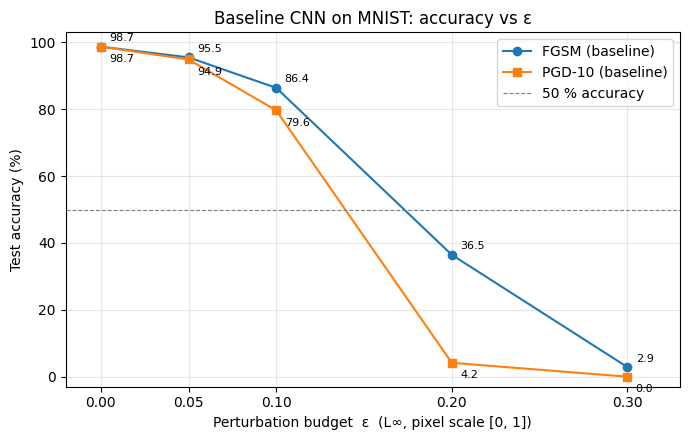

Plot saved : accuracy_vs_epsilon.png


In [13]:
eps_axis = [0.0] + EPSILONS
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(eps_axis, [fgsm_acc[e] for e in eps_axis], "o-", label="FGSM (baseline)")
ax.plot(eps_axis, [pgd_acc[e] for e in eps_axis], "s-", label="PGD-10 (baseline)")
for e in eps_axis:
    ax.annotate(f"{fgsm_acc[e]:.1f}", (e, fgsm_acc[e]), textcoords="offset points",
                xytext=(6, 4), fontsize=8)
    ax.annotate(f"{pgd_acc[e]:.1f}", (e, pgd_acc[e]), textcoords="offset points",
                xytext=(6, -11), fontsize=8)
ax.axhline(50, color="grey", ls="--", lw=0.8, label="50 % accuracy")
ax.set_xlabel("Perturbation budget  ε  (L∞, pixel scale [0, 1])")
ax.set_ylabel("Test accuracy (%)")
ax.set_title("Baseline CNN on MNIST: accuracy vs ε")
ax.set_xticks(eps_axis)
ax.set_ylim(-3, 103)
ax.set_xlim(-0.02, 0.33)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "accuracy_vs_epsilon.png"), dpi=150)
plt.show()
print("Plot saved : accuracy_vs_epsilon.png")

### Cell 14 – Save results

In [14]:
results = {
    "clean_acc": clean_acc,
    "fgsm_acc": {str(k): v for k, v in fgsm_acc.items()},
    "pgd_acc": {str(k): v for k, v in pgd_acc.items()},
    "sample_true": y5.tolist(),
    "sample_clean_pred": p_clean.tolist(),
    "sample_fgsm_pred": p_adv.tolist(),
    "misread": misread,
    "adv_clean": adv_clean,
    "adv_fgsm_0.20": adv_fgsm,
    "adv_pgd_0.20": adv_pgd,
}
with open(os.path.join(OUT_DIR, "results.json"), "w") as f:
    json.dump(results, f, indent=2)
print(json.dumps(results, indent=2))

{
  "clean_acc": 98.71,
  "fgsm_acc": {
    "0.0": 98.71,
    "0.05": 95.51,
    "0.1": 86.38,
    "0.2": 36.45,
    "0.3": 2.88
  },
  "pgd_acc": {
    "0.0": 98.71,
    "0.05": 94.88,
    "0.1": 79.64,
    "0.2": 4.15,
    "0.3": 0.0
  },
  "sample_true": [
    7,
    2,
    1,
    0,
    4
  ],
  "sample_clean_pred": [
    7,
    2,
    1,
    0,
    4
  ],
  "sample_fgsm_pred": [
    7,
    2,
    1,
    0,
    9
  ],
  "misread": [
    [
      4,
      9
    ]
  ],
  "adv_clean": 98.98,
  "adv_fgsm_0.20": 91.32,
  "adv_pgd_0.20": 75.24
}
